# Configuration decomposition

Reported fatal/injury events only; not risk per kilometre or people killed. Primary pooled periods: 2012–2016 and 2017–2021. Unknown/other remain included. The comparator is no recorded tractor, not cars only. See the durable report for all sensitivity definitions and limitations.

In [1]:
from pathlib import Path
import csv, json, math
import duckdb
from IPython.display import display, Image, Markdown
root = Path.cwd()
if not (root/'src').exists(): root = root.parent
from truck_collisions.decompose_configuration import analyze
results = analyze(root)
out = root/'reports/decomposition'
display(Markdown((out/'findings.md').read_text()))

# Configuration decomposition of fatal-event share

## Measure and method

Population: reported fatal and injury collisions, not all crashes. Tractor means NCDB type08, with or without a semitrailer. The comparator is no recorded tractor, not cars only. Fatal event means at least one death; this is not a count of people killed.

Primary periods are pooled 2012–2016 and 2017–2021, each five years. Events, rather than years, receive equal weight. For configuration k, w is its share of events and r its fatal-event share. P = Σ w r. The symmetric accounting decomposition is:

`mix = Σ (wB − wA)(rA + rB)/2`; `within = Σ (rB − rA)(wA + wB)/2`.

Multiplication by 100 gives percentage points (pp); mix + within equals the change in P. The interaction is shared equally. Polar reference allocations are exported because the allocation is not unique. Both-absent categories keep undefined rates and zero contributions. One-period-absent categories retain an unallocated entry/exit contribution rather than inventing a rate. No such one-sided category occurs in these comparisons. Unknown/other codes remain in every denominator.

## Primary results

| Cohort | Fatal/events A | Fatal/events B | Share A → B | Change pp | Mix pp | Within pp |
|---|---:|---:|---:|---:|---:|---:|
| tractor | 990/16,155 | 929/13,341 | 6.1281% → 6.9635% | 0.835362 | 0.133871 | 0.701491 |
| no_recorded_tractor | 7,736/584,822 | 7,373/480,615 | 1.3228% → 1.5341% | 0.211280 | 0.041679 | 0.169601 |

Most of the observed tractor change is within configurations. Rear-end and other single-vehicle events have large positive within contributions. Head-on events have a positive mix contribution but a negative within contribution: their fatal-event share fell. These are accounting contributions, not causes or intervention effects.

## All sensitivity comparisons

The pre2020 comparison uses five early years versus three late years; late_without_2019 uses five versus four. They are pooled event shares, not annual counts. The frozen baseline is an earlier release selection, compared separately without linking case IDs across releases.

| Source | Scenario | Cohort | Subset | Change pp | Mix pp | Within pp |
|---|---|---|---|---:|---:|---:|
| active | primary | tractor | observed | 0.835362 | 0.133871 | 0.701491 |
| active | primary | tractor | strict | 0.824303 | 0.135509 | 0.688794 |
| active | primary | no_recorded_tractor | observed | 0.211280 | 0.041679 | 0.169601 |
| active | primary | no_recorded_tractor | strict | 0.210871 | 0.041678 | 0.169193 |
| active | endpoints | tractor | observed | 1.455611 | 0.354215 | 1.101396 |
| active | endpoints | tractor | strict | 1.458874 | 0.355634 | 1.103241 |
| active | endpoints | no_recorded_tractor | observed | 0.434110 | 0.055401 | 0.378709 |
| active | endpoints | no_recorded_tractor | strict | 0.434110 | 0.055401 | 0.378709 |
| active | target_available | tractor | observed | 1.013347 | 0.202592 | 0.810756 |
| active | target_available | tractor | strict | 1.016611 | 0.203809 | 0.812802 |
| active | target_available | no_recorded_tractor | observed | 0.454424 | 0.041178 | 0.413246 |
| active | target_available | no_recorded_tractor | strict | 0.454424 | 0.041178 | 0.413246 |
| active | pre2020 | tractor | observed | 0.603388 | 0.007173 | 0.596216 |
| active | pre2020 | tractor | strict | 0.604135 | 0.007485 | 0.596650 |
| active | pre2020 | no_recorded_tractor | observed | 0.067852 | 0.021742 | 0.046110 |
| active | pre2020 | no_recorded_tractor | strict | 0.067852 | 0.021742 | 0.046110 |
| active | late_without_2019 | tractor | observed | 0.809213 | 0.131917 | 0.677295 |
| active | late_without_2019 | tractor | strict | 0.795423 | 0.133959 | 0.661464 |
| active | late_without_2019 | no_recorded_tractor | observed | 0.247856 | 0.045801 | 0.202055 |
| active | late_without_2019 | no_recorded_tractor | strict | 0.247336 | 0.045798 | 0.201538 |
| frozen_baseline | primary | tractor | observed | 0.741223 | 0.103362 | 0.637861 |
| frozen_baseline | primary | tractor | strict | 0.730173 | 0.105017 | 0.625156 |
| frozen_baseline | primary | no_recorded_tractor | observed | 0.208653 | 0.041632 | 0.167021 |
| frozen_baseline | primary | no_recorded_tractor | strict | 0.208244 | 0.041630 | 0.166613 |

## Tractor primary category accounting

Rates below are conditional on a reported casualty event. Full precision weights, counts, status flags and contributions are in category_contributions.csv.

| Code / configuration | Fatal/events A | Fatal/events B | Fatal share A → B | Mix pp | Within pp | Net pp |
|---|---:|---:|---:|---:|---:|---:|
| 01 Moving object | 5/38 | 8/28 | 13.158% → 28.571% | -0.005288 | 0.034303 | 0.029015 |
| 02 Stationary object | 18/207 | 18/190 | 8.696% → 9.474% | 0.012977 | 0.010525 | 0.023502 |
| 03 Off left shoulder | 26/742 | 24/634 | 3.504% → 3.785% | 0.005805 | 0.013151 | 0.018956 |
| 04 Off right shoulder | 30/1261 | 35/1129 | 2.379% → 3.100% | 0.017999 | 0.058649 | 0.076648 |
| 05 Rollover on roadway | 1/79 | 1/71 | 1.266% → 1.408% | 0.000577 | 0.000728 | 0.001306 |
| 06 Other single vehicle configuration | 60/1485 | 75/960 | 4.040% → 7.812% | -0.118312 | 0.309087 | 0.190775 |
| 21 Rear-end | 120/4076 | 151/3496 | 2.944% → 4.319% | 0.035385 | 0.353660 | 0.389045 |
| 22 Same-direction sideswipe | 33/1778 | 29/1591 | 1.856% → 1.823% | 0.016918 | -0.003814 | 0.013104 |
| 23 Passing left or left-turn conflict | 5/447 | 3/277 | 1.119% → 1.083% | -0.007603 | -0.000861 | -0.008463 |
| 24 Passing right or right-turn conflict | 12/358 | 2/242 | 3.352% → 0.826% | -0.008400 | -0.050889 | -0.059289 |
| 25 Other same-direction configuration | 1/25 | 0/17 | 4.000% → 0.000% | -0.000546 | -0.005644 | -0.006190 |
| 31 Head-on | 344/1021 | 297/918 | 33.692% → 32.353% | 0.185264 | -0.088415 | 0.096848 |
| 32 Approaching sideswipe | 52/532 | 57/522 | 9.774% → 10.920% | 0.064115 | 0.041257 | 0.105373 |
| 33 Left across opposing traffic | 32/532 | 25/442 | 6.015% → 5.656% | 0.001167 | -0.011856 | -0.010689 |
| 34 Right turn/conflict | 5/66 | 4/62 | 7.576% → 6.452% | 0.003941 | -0.004908 | -0.000967 |
| 35 Right angle | 133/1197 | 104/950 | 11.111% → 10.947% | -0.031827 | -0.011896 | -0.043723 |
| 36 Other different-direction configuration | 19/703 | 21/556 | 2.703% → 3.777% | -0.005961 | 0.045760 | 0.039799 |
| 41 Parked motor vehicle | 11/201 | 11/157 | 5.473% → 7.006% | -0.004204 | 0.018566 | 0.014362 |
| QQ Residual other | 67/1159 | 52/914 | 5.781% → 5.689% | -0.018535 | -0.006421 | -0.024956 |
| UU Unknown | 16/248 | 12/185 | 6.452% → 6.486% | -0.009602 | 0.000509 | -0.009092 |
| XX Not provided | 0/0 | 0/0 | undefined → undefined | 0.000000 | 0.000000 | 0.000000 |

## Allocation sensitivity: primary observed cohorts

| Cohort | Allocation | Mix pp | Within pp |
|---|---|---:|---:|
| tractor | symmetric | 0.133871 | 0.701491 |
| tractor | a_reference_rates | 0.159712 | 0.675650 |
| tractor | b_reference_rates | 0.108030 | 0.727332 |
| no_recorded_tractor | symmetric | 0.041679 | 0.169601 |
| no_recorded_tractor | a_reference_rates | 0.043428 | 0.167852 |
| no_recorded_tractor | b_reference_rates | 0.039931 | 0.171350 |

## Interpretation, validation and limits

This is a descriptive identity, with no fitted model, sampling intervals, p-values or causal attribution. Within-configuration changes can reflect changing geography, road users, weather, exposure, recording or year composition. A decline in reported injury events can increase fatal share without an increase in fatal counts or underlying physical severity. The comparator is contextual, not a matched control.

The current public record series ends in 2021. These results do not answer the intended 2016–2025 decade. Residual two-injury-event benchmark discrepancies remain in 2013 and 2019. Strict filtering, omission of 2019, pre2020, endpoint and frozen-source comparisons preserve those limitations; source changes are not manually adjusted to match publications. Configuration coding does not establish driver fault. Person-level harm is analyzed separately.

The primary within contribution remains larger than the mix contribution across the specified sensitivities. The pre2020 mix contribution is small, showing that the numerical allocation depends on the period. No pandemic effect is identified.

Reproduce with `PYTHONPATH=src .venv/bin/python -m truck_collisions.decompose_configuration`. summary.json pins input/code hashes; totals.csv, category_contributions.csv and allocation_sensitivity.csv contain inspectable full-precision results. Notebook06 adds direct event-query checks; docs/decomposition_review.md records independent replication. Generated reports are ignored build artifacts; the durable methods and findings are retained in docs/configuration_decomposition.md.


In [2]:
# Independent primary event query; does not use decomposition helpers.
con = duckdb.connect()
raw = con.execute("""SELECT is_road_tractor,C_CONF,
CASE WHEN C_YEAR <= 2016 THEN 'a' ELSE 'b' END AS period,
count(*),count(*) FILTER(WHERE C_SEV='1')
FROM read_parquet(?) WHERE C_YEAR BETWEEN 2012 AND 2021 GROUP BY ALL""",
[str(root/'data/derived/ncdb/collisions.parquet')]).fetchall()
counts = {(bool(t),code,period):(n,f) for t,code,period,n,f in raw}
rows = list(csv.DictReader((out/'category_contributions.csv').open()))
checked = 0
for tractor in (True,False):
    cohort = 'tractor' if tractor else 'no_recorded_tractor'
    ns = {p:sum(n for (t,c,q),(n,f) in counts.items() if t==tractor and q==p) for p in ('a','b')}
    for r in rows:
        if (r['source'],r['scenario'],r['subset'],r['cohort']) != ('active','primary','observed',cohort): continue
        for p in ('a','b'):
            n,f = counts.get((tractor,r['code'],p),(0,0))
            assert (int(r['events_'+p]),int(r['fatal_'+p])) == (n,f)
        n0,f0 = counts.get((tractor,r['code'],'a'),(0,0))
        n1,f1 = counts.get((tractor,r['code'],'b'),(0,0))
        if n0 and n1:
            m = 100*(n1/ns['b']-n0/ns['a'])*(f0/n0+f1/n1)/2
            v = 100*(f1/n1-f0/n0)*(n0/ns['a']+n1/ns['b'])/2
            assert math.isclose(float(r['mix_pp']),m,abs_tol=1e-11)
            assert math.isclose(float(r['within_pp']),v,abs_tol=1e-11)
        else:
            assert n0==n1==0 and r['fatal_share_a']==r['fatal_share_b']==''
        checked += 1
con.close()
print(f'Independent primary checks: {checked} configuration/cohort rows')

Independent primary checks: 42 configuration/cohort rows


In [3]:
totals = list(csv.DictReader((out/'totals.csv').open()))
methods = list(csv.DictReader((out/'allocation_sensitivity.csv').open()))
keys = ('source','scenario','cohort','subset')
for r in totals:
    delta = 100*(int(r['fatal_b'])/int(r['events_b'])-int(r['fatal_a'])/int(r['events_a']))
    assert math.isclose(delta,float(r['delta_pp']),abs_tol=1e-11)
    assert math.isclose(delta,sum(float(r[k]) for k in ('mix_pp','within_pp','unallocated_pp')),abs_tol=1e-11)
    group = [v for v in methods if all(v[k]==r[k] for k in keys)]
    assert len(group)==3
    for field in ('mix_pp','within_pp'):
        assert math.isclose(float(group[0][field]),(float(group[1][field])+float(group[2][field]))/2,abs_tol=1e-11)
print(f'{len(totals)} accounting identities and {len(methods)} allocation rows verified')
display(json.loads((out/'summary.json').read_text()))

24 accounting identities and 72 allocation rows verified


{'inputs_sha256': {'data/derived/ncdb/collisions.parquet': 'a0417eb0cb5f0da6417fce387eba7d0063362f9fd198a55117330ccd09b29688',
  'data/derived/baselines/pre_source_revision_20261015/data/derived/ncdb/collisions.parquet': 'a1b6265b43a7287ae17249a405074018cd889d5de2ef03892268e8317517b31f',
  'data/reference/collision_codebook.json': '08edc088328d85af4e3ce6284cc9b712b5d1e61bc24d7d54a4eaab81011ad910',
  'Collisions/data_dictionary.pdf': 'beef296c25eee70a55f747327b768b8da1bbdd428d02a9ca56ba781a7b6edb40',
  'data/sources.json': 'f4d313eb3a1a82db93446fba7d5e6e6ed8736263f2fdb20c8cf45e78faf309a6'},
 'code_sha256': {'src/truck_collisions/decompose_configuration.py': '360bf7df060688586c486225bbc079b59a3d94215c10b4b643d3f1442d783267',
  'src/truck_collisions/analyze_conditions.py': 'ae6d3acbe5f09f8de025f53525c9d04071f89aece551451a7e3d2b31b88bf19b',
  'src/truck_collisions/audit_conditions.py': '834c70b996befee17bae5a51d079275aa7486623236a28ad59ad9215d55ba1ed',
  'src/truck_collisions/build.py': 'a

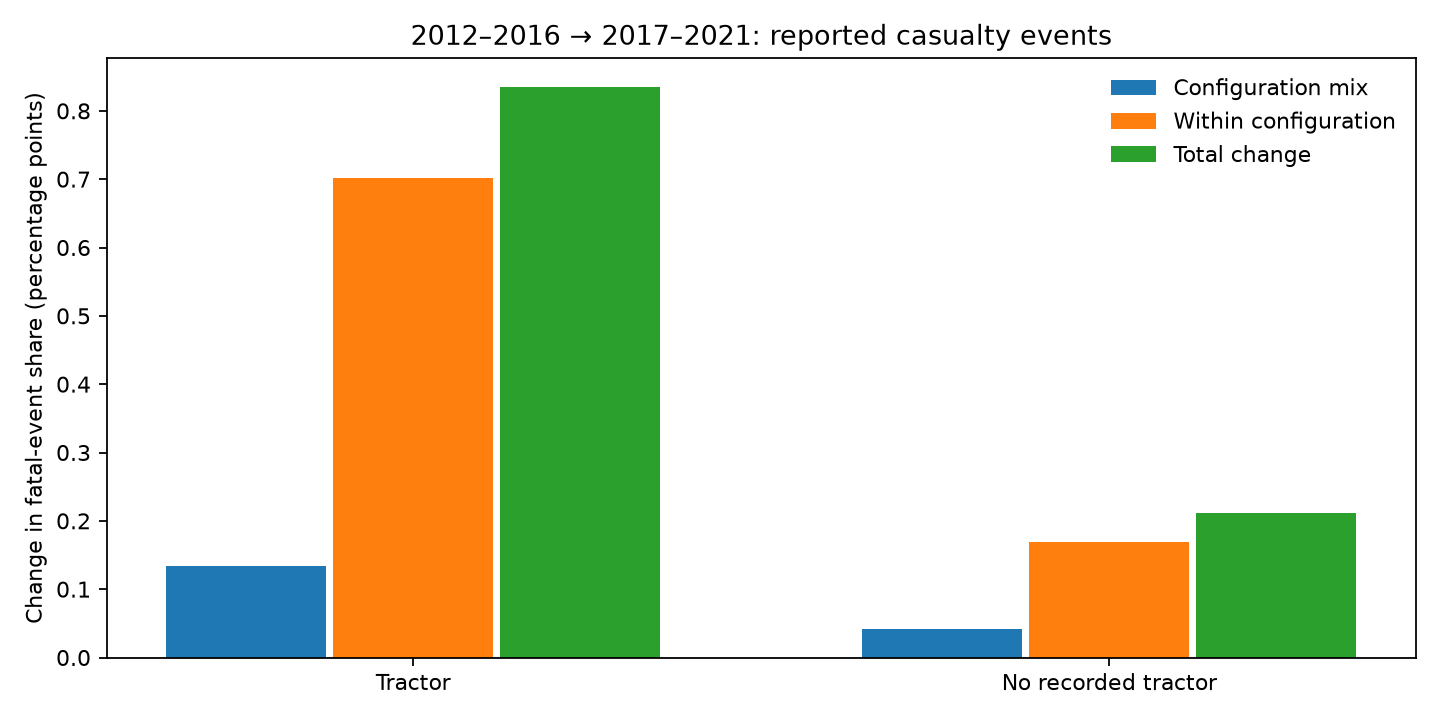

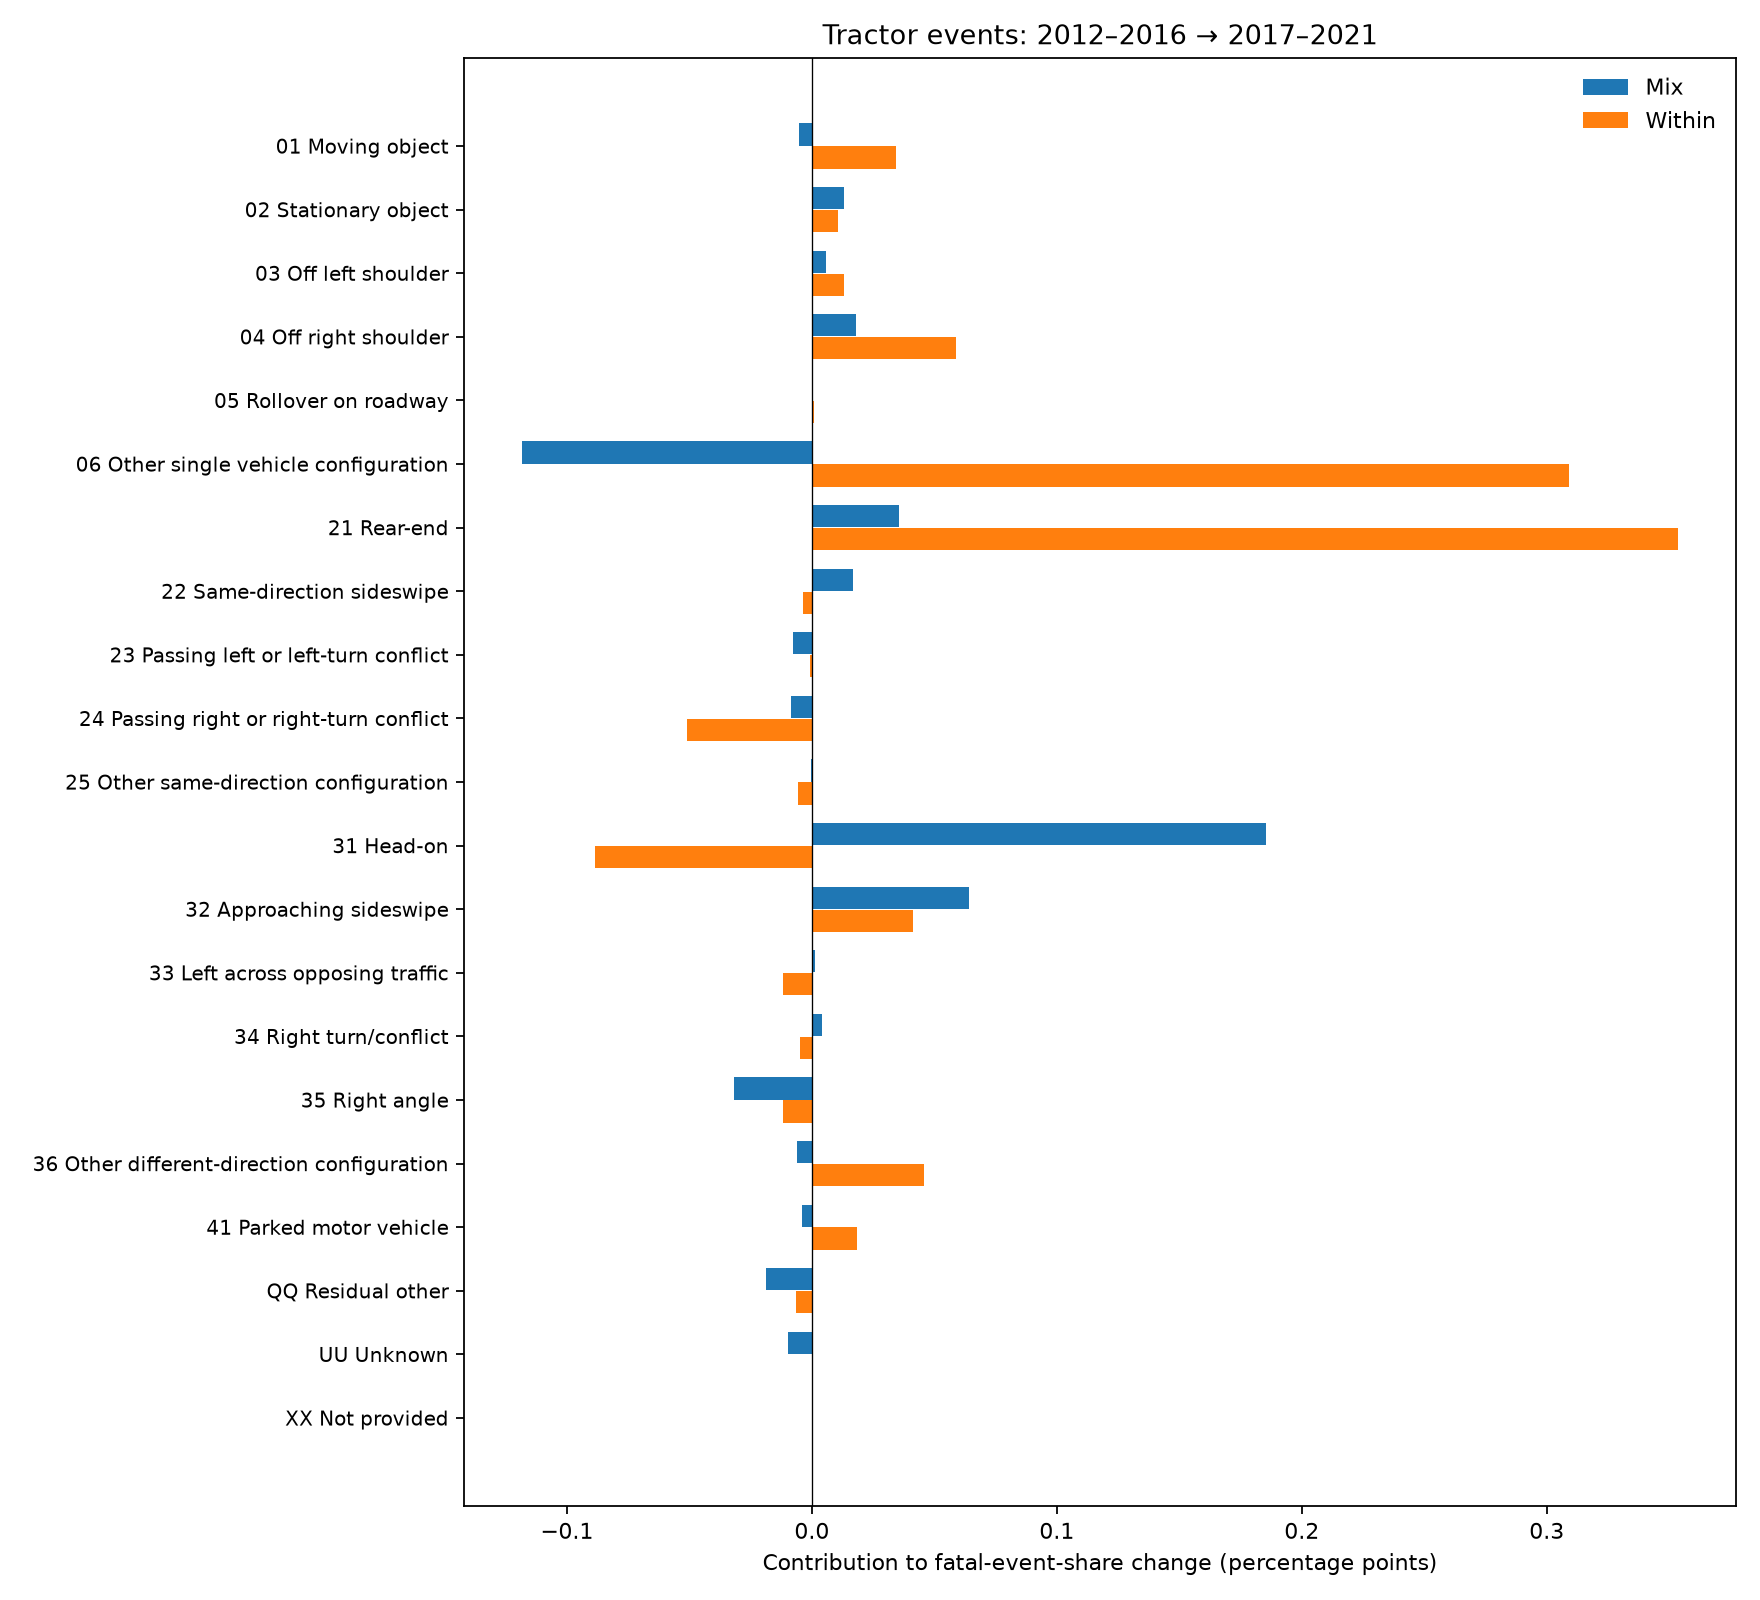

In [4]:
display(Image(filename=str(out/'components.png')))
display(Image(filename=str(out/'configuration_contributions.png')))

## Interpretation gate

Within-configuration change dominates the specified tractor comparisons. It can still reflect other changing characteristics and injury reporting. Head-on within-category fatal share declines in the primary comparison; do not say all categories became more fatal. Latest-decade coverage, compatible exposure and person-record uncertainty remain unresolved. Next priority: audit exposure compatibility before estimating driving risk.